**Course:** DSC550  
**Student:** Anil Bammidi  

**CNN Digit Classifier on MNIST (PyTorch)**

This notebook completes the following tasks:

1. Load the MNIST dataset  
2. Display the first five training images and compare to their labels  
3. Build and train a CNN classifier on MNIST  
4. Report test accuracy  
5. Display a confusion matrix  
6. Summarize results  

Note: MNIST is downloaded automatically the first time you run this notebook. If your environment blocks downloads, run once on a machine with internet or pre-download MNIST to the default `./data` folder.


In [32]:
# Imports
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms



import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score


In [33]:
# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device


device(type='cpu')

In [34]:
# Step 1: Load the MNIST dataset
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_ds = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
test_ds  = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

print("Train size:", len(train_ds))
print("Test size :", len(test_ds))


Train size: 60000
Test size : 10000


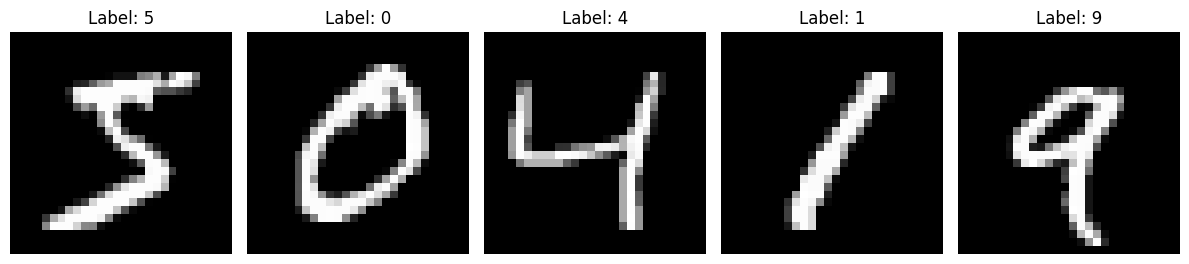

First 5 training labels: [5, 0, 4, 1, 9]


In [35]:
# Step 2: Display the first five images and their labels
fig, axes = plt.subplots(1, 5, figsize=(12, 3))
for i in range(5):
    img, label = train_ds[i]
    axes[i].imshow(img.squeeze().numpy() * 0.3081 + 0.1307, cmap="gray")
    axes[i].set_title(f"Label: {label}")
    axes[i].axis("off")
plt.tight_layout()
plt.show()

print("First 5 training labels:", [train_ds[i][1] for i in range(5)])


In [36]:
# Step 3: Build a CNN classifier (two convolution layers, two fully connected layers)

class MNISTCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)   # 32x28x28
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)  # 64x28x28
        self.pool = nn.MaxPool2d(2, 2)                            # 64x14x14
        self.dropout = nn.Dropout(0.25)
        self.fc1 = nn.Linear(64 * 14 * 14, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.dropout(x)
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

model = MNISTCNN().to(device)
model


MNISTCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout): Dropout(p=0.25, inplace=False)
  (fc1): Linear(in_features=12544, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)

In [37]:
# Train / Eval helpers
batch_size = 128
train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=0)
test_loader  = DataLoader(test_ds, batch_size=batch_size, shuffle=False, num_workers=0)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

def train_one_epoch(model, loader):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for X, y in loader:
        X, y = X.to(device), y.to(device)
        optimizer.zero_grad()
        logits = model(X)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * X.size(0)
        preds = logits.argmax(dim=1)
        correct += (preds == y).sum().item()
        total += y.size(0)
    return running_loss / total, correct / total

@torch.no_grad()
def eval_model(model, loader):
    model.eval()
    all_preds, all_true = [], []
    for X, y in loader:
        X = X.to(device)
        logits = model(X)
        preds = logits.argmax(dim=1).cpu().numpy()
        all_preds.append(preds)
        all_true.append(y.numpy())
    y_pred = np.concatenate(all_preds)
    y_true = np.concatenate(all_true)
    return y_true, y_pred, accuracy_score(y_true, y_pred)

# Step 3 (cont.): Train the CNN
epochs = 3  # raise to 5-10 for higher accuracy
for epoch in range(1, epochs + 1):
    train_loss, train_acc = train_one_epoch(model, train_loader)
    y_true, y_pred, test_acc = eval_model(model, test_loader)
    print(f"Epoch {epoch:02d} | train loss {train_loss:.4f} | train acc {train_acc:.4f} | test acc {test_acc:.4f}")


Epoch 01 | train loss 0.1795 | train acc 0.9444 | test acc 0.9849
Epoch 02 | train loss 0.0561 | train acc 0.9830 | test acc 0.9855
Epoch 03 | train loss 0.0412 | train acc 0.9873 | test acc 0.9889


In [38]:
# Step 4: Report test accuracy
_, _, test_acc = eval_model(model, test_loader)
print(f"Final Test Accuracy: {test_acc:.4f}")


Final Test Accuracy: 0.9889


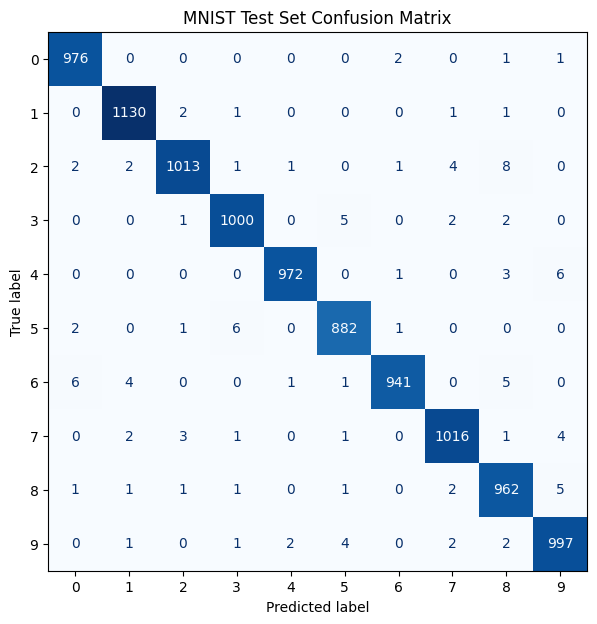

In [39]:
# Step 5: Confusion matrix on the test set
y_true, y_pred, _ = eval_model(model, test_loader)
cm = confusion_matrix(y_true, y_pred, labels=list(range(10)))

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=list(range(10)))
fig, ax = plt.subplots(figsize=(7, 7))
disp.plot(ax=ax, cmap="Blues", colorbar=False)
plt.title("MNIST Test Set Confusion Matrix")
plt.show()


## Step 6: Results Summary

The CNN was trained on the MNIST training set and evaluated on the MNIST test set. The test accuracy reported above measures how well the model generalizes to unseen handwritten digits. The confusion matrix highlights which digits are most often confused, which can point to similar handwriting patterns (for example, some 4s may look like 9s). Accuracy can typically be improved by training for more epochs, adding a learning-rate scheduler, and experimenting with deeper architectures or mild data augmentation.

**Evaluation note:** Test accuracy was printed after every epoch for monitoring. The notebook has no separate validation split, so the test set was seen during training. The reported 98.89% is the accuracy of the model after three epochs. If the epoch count was chosen by looking at test scores, that figure overstates performance on unseen data. A validation split (for example, holding back 5,000 training images) would give an unbiased estimate and is the recommended next step.